# Bike Shop Data Exploration

Import pandas and load dataset

In [2]:
import pandas as pd

order_data = pd.read_csv("bike_shop_orders.csv")

print(order_data.info())
print(f"(Rows, Columns) {order_data.shape}")

<class 'pandas.DataFrame'>
RangeIndex: 1194 entries, 0 to 1193
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   order_id          1194 non-null   str  
 1   order_date        1194 non-null   str  
 2   customer_id       1194 non-null   str  
 3   city              1180 non-null   str  
 4   membership_type   1194 non-null   str  
 5   channel           1194 non-null   str  
 6   product_category  1194 non-null   str  
 7   product           1194 non-null   str  
 8   quantity          1194 non-null   int64
 9   unit_price        1194 non-null   int64
dtypes: int64(2), str(8)
memory usage: 93.4 KB
None
(Rows, Columns) (1194, 10)


In [3]:
order_data.head()

,order_id,order_date,customer_id,city,membership_type,channel,product_category,product,quantity,unit_price
0,SC-50001,2025-11-01,C1282,Edmonton,Non-member,Online,Clothing,Jersey,1,85
1,SC-50002,2025-11-01,C1503,Spruce Grove,Basic,In-store,Clothing,Winter balaclava,1,29
2,SC-50003,2025-11-02,C1534,Leduc,Non-member,Online,Accessories,Light set,1,65
3,SC-50004,2025-11-02,C1008,Edmonton,Non-member,In-store,Accessories,Lock,2,59
4,SC-50005,2025-11-02,C1298,Edmonton,Basic,In-store,Clothing,Jersey,2,85


In [4]:
order_data["quantity"].describe()

count    1194.000000
mean        1.679229
std         2.778215
min        -1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        60.000000
Name: quantity, dtype: float64

In [5]:
order_data["city"].value_counts()

city
Edmonton          733
St. Albert        136
Sherwood Park     109
Spruce Grove       92
Leduc              91
St Albert           9
edmonton            6
Sherwood Park       4
Name: count, dtype: int64

In [6]:
edmonton_orders = order_data[order_data["city"] == "Edmonton"]
edmonton_orders.head()

,order_id,order_date,customer_id,city,membership_type,channel,product_category,product,quantity,unit_price
0,SC-50001,2025-11-01,C1282,Edmonton,Non-member,Online,Clothing,Jersey,1,85
3,SC-50004,2025-11-02,C1008,Edmonton,Non-member,In-store,Accessories,Lock,2,59
4,SC-50005,2025-11-02,C1298,Edmonton,Basic,In-store,Clothing,Jersey,2,85
7,SC-50008,2025-11-03,C1119,Edmonton,Premium,In-store,Clothing,Cycling gloves,1,35
8,SC-50009,2025-11-04,C1436,Edmonton,Non-member,In-store,Clothing,Jersey,2,85


In [7]:
top_orders = edmonton_orders.sort_values(by="quantity", ascending=False)
top_orders

,order_id,order_date,customer_id,city,membership_type,channel,product_category,product,quantity,unit_price
681,SC-50680,2026-06-09,C1644,Edmonton,Non-member,In-store,Accessories,Water bottle,60,14
490,SC-50491,2026-05-02,C1642,Edmonton,Premium,In-store,Parts,Inner tube,30,12
70,SC-50071,2025-12-04,C1648,Edmonton,Premium,In-store,Clothing,Cycling gloves,30,35
1134,SC-51132,2026-10-11,C1502,Edmonton,Premium,In-store,Parts,Inner tube,6,12
121,SC-50122,2025-12-13,C1432,Edmonton,Premium,In-store,Parts,Inner tube,6,12
...,...,...,...,...,...,...,...,...,...,...
1169,SC-51167,2026-10-23,C1587,Edmonton,Basic,In-store,Clothing,Cycling gloves,1,35
1168,SC-51166,2026-10-21,C1640,Edmonton,Basic,In-store,Accessories,Lock,1,59
1166,SC-51164,2026-10-20,C1464,Edmonton,Premium,Online,Bikes,Road bike,1,1649
1163,SC-51161,2026-10-19,C1005,Edmonton,Non-member,In-store,Bikes,Road bike,1,1649


In [8]:
city_by_channel = order_data.groupby("city")["channel"].value_counts()

city_by_channel

city            channel 
Edmonton        In-store    493
                Online      240
Leduc           In-store     53
                Online       38
Sherwood Park   In-store     73
                Online       36
Sherwood Park   In-store      3
                Online        1
Spruce Grove    In-store     58
                Online       34
St Albert       In-store      9
St. Albert      In-store     91
                Online       45
edmonton        In-store      5
                Online        1
Name: count, dtype: int64

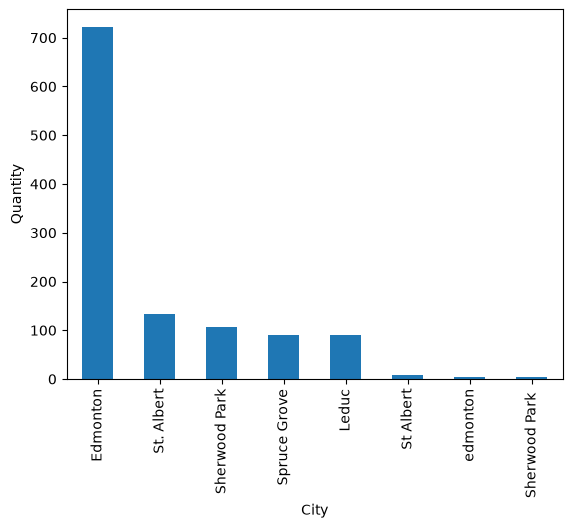

In [ ]:
import matplotlib.pyplot as plt



mask = (order_data['quantity'] > 0) & (order_data['quantity'] < 5)

filter_order_data = order_data[mask]
# in class i missed this step, we need to create a new series of value counts, and then plot that rather than our filtered order data
category_counts = filter_order_data["city"].value_counts()
category_counts.plot.bar(x='city', y='quantity')
plt.xlabel("City")
plt.ylabel("Quantity")
plt.show()